Problem: A telecom company loses about 26.5% of its customers. It cannot call every customer, so it needs to know which ones are most likely to leave.
Objective: Build a model that predicts churn and ranks customers by risk.
Scope: 7,043 customers from the IBM Telco dataset.
Success: ROC-AUC above 0.80 and recall above 0.75 on unseen data, since missing a leaving customer is costly.
Output: A risk score per customer and recommendations for the retention team.

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind
sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
for c in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
print(df.shape, "| churn rate: %.2f%%" % (df.ChurnFlag.mean() * 100))

(7043, 22) | churn rate: 26.54%


In [8]:
# Is contract type really linked to churn? (chi-square test)
chi, p, _, _ = chi2_contingency(pd.crosstab(df["Contract"], df["ChurnFlag"]))
print("Contract vs churn: chi2 = %.1f, p = %.2e" % (chi, p))

# Do churned customers have a different tenure? (t-test)
t, p2 = ttest_ind(df[df.ChurnFlag == 1].tenure, df[df.ChurnFlag == 0].tenure, equal_var=False)
print("Tenure difference: t = %.1f, p = %.2e" % (t, p2))

Contract vs churn: chi2 = 1184.6, p = 5.86e-258
Tenure difference: t = -34.8, p = 1.20e-232


In [9]:
df["AvgChargePerMonth"] = df["TotalCharges"] / df["tenure"].replace(0, 1)
svc = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["NumServices"] = (df[svc] == "Yes").sum(axis=1)
df["IsNew"] = (df["tenure"] <= 12).astype(int)
df["AutoPay"] = df["PaymentMethod"].str.contains("automatic").astype(int)
df["MTM_Fiber"] = ((df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic")).astype(int)

X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "ChurnFlag"]), drop_first=True)
y = df["ChurnFlag"]
print("Number of features:", X.shape[1])

Number of features: 28


In [15]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
rows, probs = [], {}
for name, m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=5, scoring="roc_auc").mean()
    m.fit(Xtr, ytr)
    pr = m.predict_proba(Xte)[:, 1]
    pred = (pr >= 0.5).astype(int)
    probs[name] = pr
    rows.append(dict(Model=name, CV_AUC=cv, Accuracy=accuracy_score(yte, pred), Precision=precision_score(yte, pred),
                     Recall=recall_score(yte, pred), F1=f1_score(yte, pred), AUC=roc_auc_score(yte, pr)))
results = pd.DataFrame(rows).round(3)
results

,Model,CV_AUC,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.846,0.734,0.499,0.791,0.612,0.841
1,Random Forest,0.839,0.777,0.568,0.671,0.615,0.839
2,Gradient Boosting,0.845,0.799,0.652,0.521,0.579,0.843


In [17]:
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
                  {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="roc_auc")
gs.fit(Xtr, ytr)
best = gs.best_estimator_
pb = best.predict_proba(Xte)[:, 1]
print("Best setting:", gs.best_params_, "| CV AUC: %.3f | Test AUC: %.3f" % (gs.best_score_, roc_auc_score(yte, pb)))

for th in [0.3, 0.4, 0.5, 0.6]:
    pr = (pb >= th).astype(int)
    print("Threshold", th, "| precision %.2f | recall %.2f | f1 %.2f" % (precision_score(yte, pr), recall_score(yte, pr), f1_score(yte, pr)))

Best setting: {'logisticregression__C': 10} | CV AUC: 0.846 | Test AUC: 0.840
Threshold 0.3 | precision 0.43 | recall 0.93 | f1 0.59
Threshold 0.4 | precision 0.47 | recall 0.86 | f1 0.61
Threshold 0.5 | precision 0.50 | recall 0.78 | f1 0.61
Threshold 0.6 | precision 0.55 | recall 0.71 | f1 0.62


In [18]:
from sklearn.metrics import confusion_matrix
pred = (pb >= 0.5).astype(int)
cm = confusion_matrix(yte, pred)
print(cm)

err = Xte.copy(); err["actual"] = yte.values; err["pred"] = pred
fn = err[(err.actual == 1) & (err.pred == 0)]   # churners we missed
fp = err[(err.actual == 0) & (err.pred == 1)]   # false alarms
tp = err[(err.actual == 1) & (err.pred == 1)]   # churners we caught
print("Missed churners:", len(fn), "| False alarms:", len(fp))
print("Avg tenure - missed: %.1f | caught: %.1f" % (fn.tenure.mean(), tp.tenure.mean()))
print("False alarms that are month-to-month fiber: %.0f%%" % (fp.MTM_Fiber.mean() * 100))

[[739 296]
 [ 82 292]]
Missed churners: 82 | False alarms: 296
Avg tenure - missed: 28.2 | caught: 13.2
False alarms that are month-to-month fiber: 62%


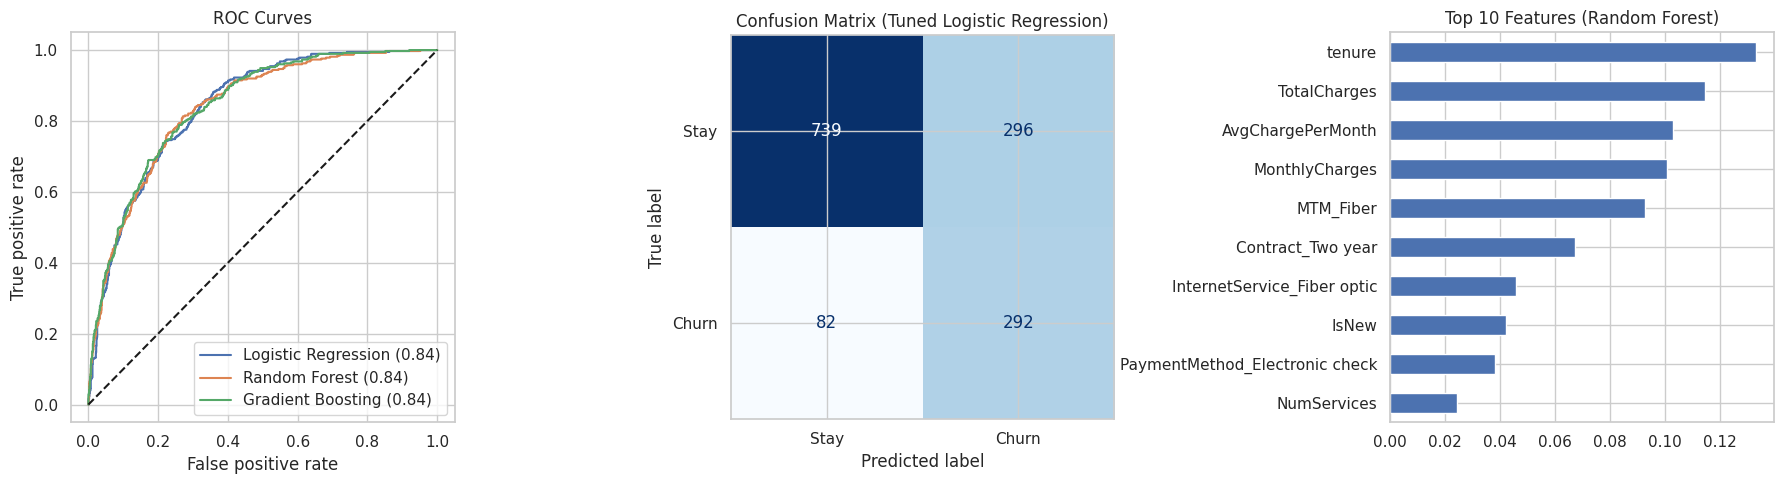

,customers,churn_rate
band,,
Low,600,4.5
Medium,325,24.6
High,484,55.2


In [19]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for n, p_ in probs.items():
    f, t_, _ = roc_curve(yte, p_)
    ax[0].plot(f, t_, label=f"{n} ({roc_auc_score(yte, p_):.2f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC Curves"); ax[0].legend()
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")

ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title("Confusion Matrix (Tuned Logistic Regression)")

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp[::-1].plot.barh(ax=ax[2], color="#4c72b0"); ax[2].set_title("Top 10 Features (Random Forest)")
plt.tight_layout(); plt.show()

# Risk bands
bands = pd.cut(pb, [0, .3, .6, 1], labels=["Low", "Medium", "High"])
rb = pd.DataFrame({"band": bands, "actual": yte.values}).groupby("band", observed=True).agg(customers=("actual", "count"), churn_rate=("actual", "mean"))
rb["churn_rate"] = (rb.churn_rate * 100).round(1)
rb